In [30]:
# Import required libraries
import tensorflow as tf
import tf_keras as keras
from keras import layers
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.applications import Xception
from tensorflow.keras.applications.xception import preprocess_input
import tensorflow_model_optimization as tfmot
import matplotlib.pyplot as plt
import numpy as np
import tempfile
import os

In [31]:
# Step 1: Load the cifar10 dataset

# X_train and X_test contain the images
# y_train and y_test contain the corresponding labels
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


In [32]:
# Step 2: Define the cifar10 class names

class_names = [
    "airplane",
	"automobile",
	"bird",
	"cat",
	"deer",
	"dog",
	"frog",
	"horse",
	"ship",
	"truck"
]
print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)



Training images: (50000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)


In [33]:
# Step 4: Build the CNN model

IMAGE_SIZE = 150

base_model = Xception(
    weights="imagenet",
    include_top=False,
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
)

base_model.trainable = False

inputs = keras.Input(shape=(32, 32, 3))

x = keras.layers.Resizing(IMAGE_SIZE, IMAGE_SIZE)(inputs)

x = preprocess_input(x)

x = base_model(x, training=False)

x = keras.layers.GlobalAveragePooling2D()(x)

outputs = keras.layers.Dense(10, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 resizing_1 (Resizing)       (None, 150, 150, 3)       0         
                                                                 
 tf.math.truediv_1 (TFOpLam  (None, 150, 150, 3)       0         
 bda)                                                            
                                                                 
 tf.math.subtract_1 (TFOpLa  (None, 150, 150, 3)       0         
 mbda)                                                           
                                                                 
 xception (Functional)       (None, 5, 5, 2048)        20861480  
                                                                 
 global_average_pooling2d_1  (None, 2048)              0   

In [34]:
# Step 5: Compile the model

model.compile(
    optimizer=keras.optimizers.Adam(),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy()]
)

In [35]:
# Step 6: Train the model

history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/5
625/625 [==============================] - 22s 33ms/step - loss: 0.5624 - sparse_categorical_accuracy: 0.8160 - val_loss: 0.4711 - val_sparse_categorical_accuracy: 0.8419
Epoch 2/5
625/625 [==============================] - 20s 32ms/step - loss: 0.4276 - sparse_categorical_accuracy: 0.8565 - val_loss: 0.4392 - val_sparse_categorical_accuracy: 0.8526
Epoch 3/5
625/625 [==============================] - 20s 32ms/step - loss: 0.3885 - sparse_categorical_accuracy: 0.8681 - val_loss: 0.4474 - val_sparse_categorical_accuracy: 0.8513
Epoch 4/5
625/625 [==============================] - 20s 32ms/step - loss: 0.3608 - sparse_categorical_accuracy: 0.8780 - val_loss: 0.4316 - val_sparse_categorical_accuracy: 0.8540
Epoch 5/5
625/625 [==============================] - 20s 32ms/step - loss: 0.3369 - sparse_categorical_accuracy: 0.8853 - val_loss: 0.4401 - val_sparse_categorical_accuracy: 0.8538


In [36]:
# Step 7: Evaluate the model

baseline_test_loss, baseline_model_accuracy = model.evaluate(X_test, y_test)

print(f"\nBaseline Test Loss: {baseline_test_loss:.4f}")
print(f"Baseline Test Accuracy: {baseline_model_accuracy:.2%}")

313/313 [==============================] - 5s 16ms/step - loss: 0.4505 - sparse_categorical_accuracy: 0.8494

Baseline Test Loss: 0.4505
Baseline Test Accuracy: 84.94%


In [53]:
# define prune parameters

prune_low_magnitude = tfmot.sparsity.keras.prune_low_magnitude

batch_size = 64
pruning_epochs = 5
validation_split = 0.1

num_images = X_train.shape[0] * (1 - validation_split)

end_step = (
    np.ceil(num_images / batch_size).astype(np.int32)
    * pruning_epochs
)

pruning_params = {
    "pruning_schedule": tfmot.sparsity.keras.PolynomialDecay(
        initial_sparsity=0.50,
        final_sparsity=0.80,
        begin_step=0,
        end_step=end_step
    )
}

print("\nNumber of training examples used for pruning:", int(num_images))
print("Pruning schedule end step:", end_step)




Number of training examples used for pruning: 45000
Pruning schedule end step: 3520


In [59]:
pruned_dense = prune_low_magnitude(
    model.layers[-1],
    **pruning_params
)

model_for_pruning = keras.Model(
    inputs=model.input,
    outputs=pruned_dense(model.layers[-2].output)
)

model_for_pruning.compile(
    optimizer=keras.optimizers.Adam(),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy()]
)

model_for_pruning.summary()

Model: "model_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 resizing_1 (Resizing)       (None, 150, 150, 3)       0         
                                                                 
 tf.math.truediv_1 (TFOpLam  (None, 150, 150, 3)       0         
 bda)                                                            
                                                                 
 tf.math.subtract_1 (TFOpLa  (None, 150, 150, 3)       0         
 mbda)                                                           
                                                                 
 xception (Functional)       (None, 5, 5, 2048)        20861480  
                                                                 
 global_average_pooling2d_1  (None, 2048)              0   

In [60]:
logdir = tempfile.mkdtemp()

callbacks = [
    tfmot.sparsity.keras.UpdatePruningStep(),
]

model_for_pruning.compile(
    optimizer=keras.optimizers.Adam(),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=[keras.metrics.SparseCategoricalAccuracy()]
)
pruned_history = model_for_pruning.fit(
    X_train,
    y_train,
    epochs=pruning_epochs,
    batch_size=batch_size,
    validation_split=validation_split,
    callbacks=callbacks
)

Epoch 1/5
704/704 [==============================] - 25s 33ms/step - loss: 0.3237 - sparse_categorical_accuracy: 0.8888 - val_loss: 0.4589 - val_sparse_categorical_accuracy: 0.8500
Epoch 2/5
704/704 [==============================] - 23s 33ms/step - loss: 0.3087 - sparse_categorical_accuracy: 0.8940 - val_loss: 0.4551 - val_sparse_categorical_accuracy: 0.8494
Epoch 3/5
704/704 [==============================] - 23s 33ms/step - loss: 0.3055 - sparse_categorical_accuracy: 0.8955 - val_loss: 0.4601 - val_sparse_categorical_accuracy: 0.8500
Epoch 4/5
704/704 [==============================] - 23s 33ms/step - loss: 0.3064 - sparse_categorical_accuracy: 0.8956 - val_loss: 0.4587 - val_sparse_categorical_accuracy: 0.8500
Epoch 5/5
704/704 [==============================] - 23s 33ms/step - loss: 0.3056 - sparse_categorical_accuracy: 0.8945 - val_loss: 0.4605 - val_sparse_categorical_accuracy: 0.8508


In [61]:
pruned_test_loss, model_for_pruning_accuracy = (
    model_for_pruning.evaluate(
        X_test,
        y_test,
        verbose=0
    )
)

print("\nBaseline Test Accuracy:", f"{baseline_model_accuracy:.2%}")
print("Pruned Test Accuracy:", f"{model_for_pruning_accuracy:.2%}")
print("Pruned Test Loss:", f"{pruned_test_loss:.4f}")


Baseline Test Accuracy: 84.94%
Pruned Test Accuracy: 84.56%
Pruned Test Loss: 0.4739


313/313 [==============================] - 4s 12ms/step


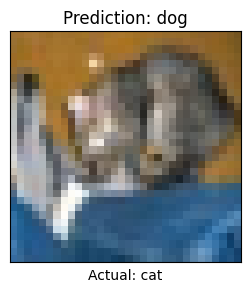

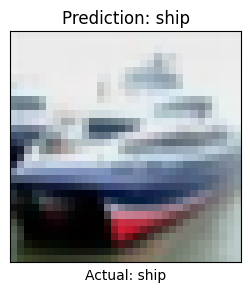

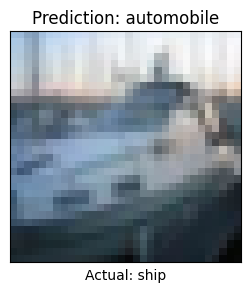

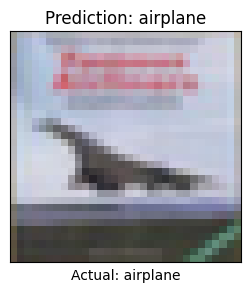

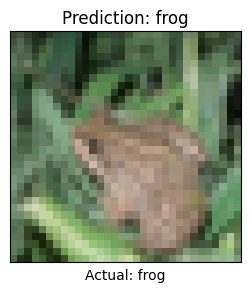

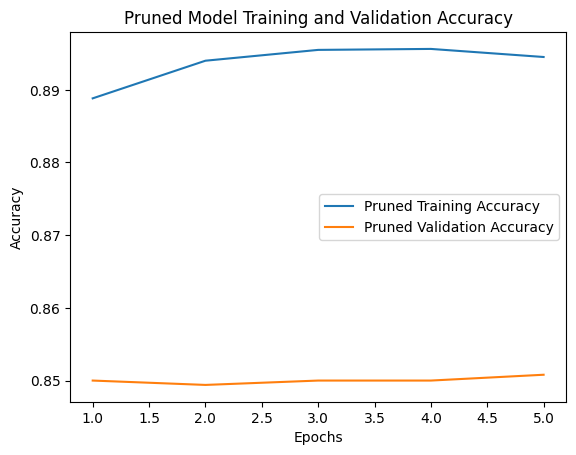

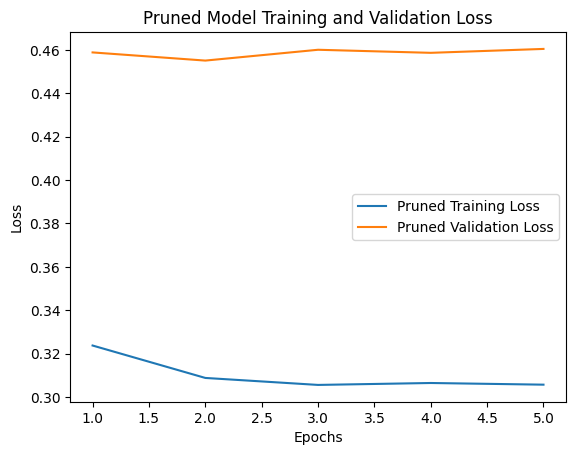

In [62]:
# predictions for pruned model

predictions = model_for_pruning.predict(X_test)

# display the first five predictions
for i in range(5):
    plt.figure(figsize=(3, 3))
    plt.imshow(X_test[i])
    plt.grid(False)
    plt.xticks([])
    plt.yticks([])

    actual_class = class_names[int(y_test[i][0])]
    predicted_class = class_names[np.argmax(predictions[i])]

    plt.xlabel("Actual: " + actual_class)
    plt.title("Prediction: " + predicted_class)
    plt.show()


pruned_epochs = range(1, len(pruned_history.history["sparse_categorical_accuracy"]) + 1)

# Training and validation accuracy
plt.figure()
plt.plot(pruned_epochs, pruned_history.history["sparse_categorical_accuracy"], label="Pruned Training Accuracy")
plt.plot(
    pruned_epochs,
    pruned_history.history["val_sparse_categorical_accuracy"],
    label="Pruned Validation Accuracy"
)
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Pruned Model Training and Validation Accuracy")
plt.legend()
plt.show()

# Training and validation loss
plt.figure()
plt.plot(pruned_epochs, pruned_history.history["loss"], label="Pruned Training Loss")
plt.plot(
    pruned_epochs,
    pruned_history.history["val_loss"],
    label="Pruned Validation Loss"
)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Pruned Model Training and Validation Loss")
plt.legend()
plt.show()


313/313 [==============================] - 4s 13ms/step


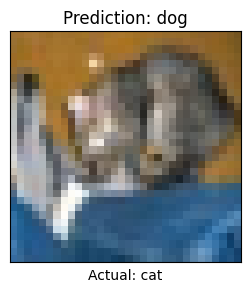

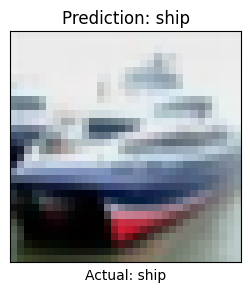

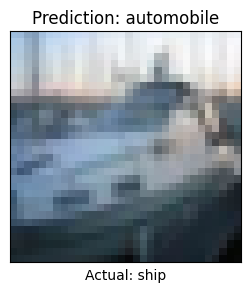

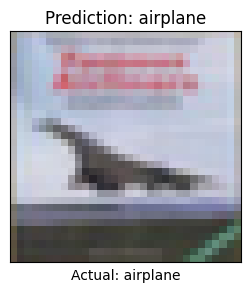

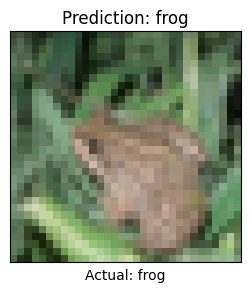

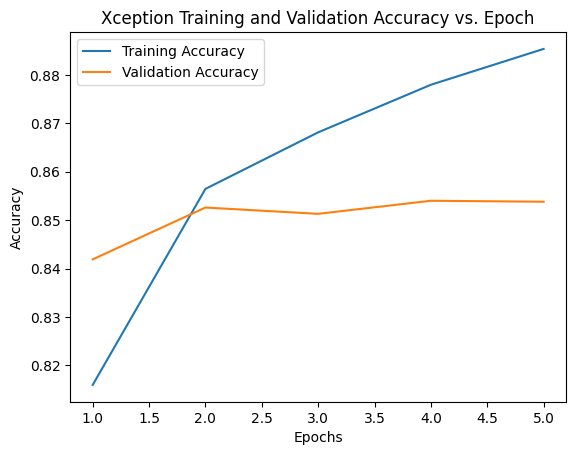

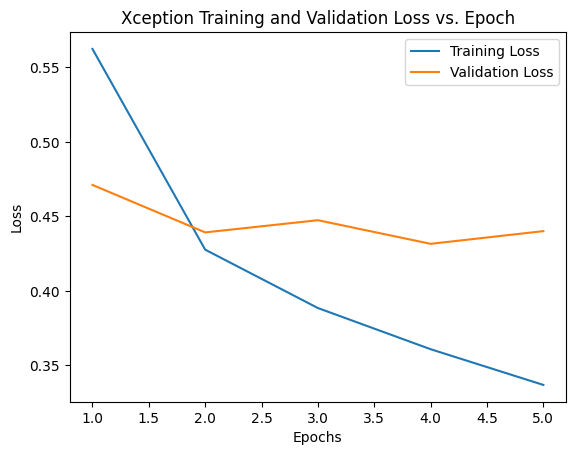

dict_keys(['loss', 'sparse_categorical_accuracy', 'val_loss', 'val_sparse_categorical_accuracy'])


In [63]:
# Step 8: Make predictions

#  Display the first five predictions
predictions = model.predict(X_test)

for i in range(5):

    plt.figure(figsize=(3, 3))

    plt.imshow(X_test[i])

    plt.grid(False)
    plt.xticks([])
    plt.yticks([])

    actual_class = class_names[y_test[i][0]]
    predicted_class = class_names[np.argmax(predictions[i])]

    plt.xlabel("Actual: " + actual_class)
    plt.title("Prediction: " + predicted_class)
    plt.show()


# part 3: analyze training results
# training and validation acc. vs epoch
epochs = range(1, len(history.history["sparse_categorical_accuracy"]) + 1)
plt.figure()
plt.plot(epochs, history.history["sparse_categorical_accuracy"], label="Training Accuracy")
plt.plot(epochs, history.history["val_sparse_categorical_accuracy"], label="Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Xception Training and Validation Accuracy vs. Epoch")
plt.legend()
plt.show()

# training and validation loss vs epoch
plt.figure()
plt.plot(epochs, history.history["loss"], label="Training Loss")
plt.plot(epochs, history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Xception Training and Validation Loss vs. Epoch")
plt.legend()
plt.show()
print(history.history.keys())